<a href="https://colab.research.google.com/github/gitmystuff/INFO5810/blob/main/Module_11-Causal_Discovery/Module11_Causal_Discovery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 11 — Causal Discovery: Finding the Arrows Instead of Being Given Them

Your Name

## Getting Started

* Colab - get notebook from gitmystuff INFO5810 repository
* Save a Copy in Drive
* Remove Copy of
* Edit your name in the cell above and the filename
* Clean up Colab Notebooks folder
* Submit shared link


**Objective:** Learn why correlation does not equal
causation, and discover how algorithms can automatically uncover
cause-and-effect arrows from data.

**Key topics:** Correlation vs. Causation · Directed Acyclic Graphs (DAGs) ·
Constraint-based search (PC, or Peter–Clark algorithm) · Score-based search (GES - Greedy Equivalence Search) · Latent
confounding.



## Setup

Same libraries as before, plus `networkx` -- which, worth saying plainly,
you have already been using this whole time without it being named.
`pgmpy`'s `DiscreteBayesianNetwork` is, underneath, literally a
`networkx.DiGraph` with CPTs bolted on. This module just stops hiding that
and uses `networkx` directly for a few things.


A Discrete Bayesian Network is a probabilistic graphical model that represents a set of discrete random variables and their conditional dependencies using a Directed Acyclic Graph (DAG).

Annie Duke’s book Thinking in Bets argues that real life is like poker, not chess. In chess, there is no hidden information and very little luck; a bad move causes a loss, and a good move guarantees a win. In poker—and in life—you deal with incomplete information, hidden variables, and luck. Every major life choice (such as a career move, buying a home, or a relationship) is a bet on an uncertain future. Instead of viewing choices as black-and-white (right or wrong), probabilistic thinking changes how you make and evaluate decisions.

Key Characteristics

* Nodes and Edges: Each node represents a discrete random variable with a finite number of mutually exclusive states (e.g., Yes/No, Low/Medium/High). Directed edges (arrows) represent direct causal or statistical dependencies between variables.
* No Cycles: The graph is acyclic, meaning you cannot follow the arrows to loop back to a starting node, which prevents feedback loops in reasoning.
* Conditional Probability Tables (CPTs): Because the variables are discrete, the quantitative relationship between a child node and its parent nodes is defined using a CPT. This table explicitly lists the probability of every possible state of the child variable for every combination of parent states.
* Joint Probability Factorization: The network breaks down a complex global joint probability distribution into a product of local conditional probabilities for each node given its parents:
$\mathbb{P}(X_{1},X_{2},\dots ,X_{n})=\prod _{r=1}^{n}\mathbb{P}(X_{r}\mid \pi _{r})$
where $\pi _{r}$ represents the parents of variable $X_{r}$.

Common Uses

* Inference and Diagnostics: Updating the probability of target states (like a medical diagnosis or system failure) when new evidence or observations are introduced.
* Uncertainty Modeling: Making predictions and reasoning under conditions of incomplete, noisy, or missing data.
* Domain Applications: Used in medical diagnosis, fault detection in engineering, bioinformatics, and risk analysis.


In [ ]:
%pip install -q pgmpy

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.width", 120)
plt.rcParams["figure.facecolor"] = "white"

print("Libraries loaded.")

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Libraries loaded.


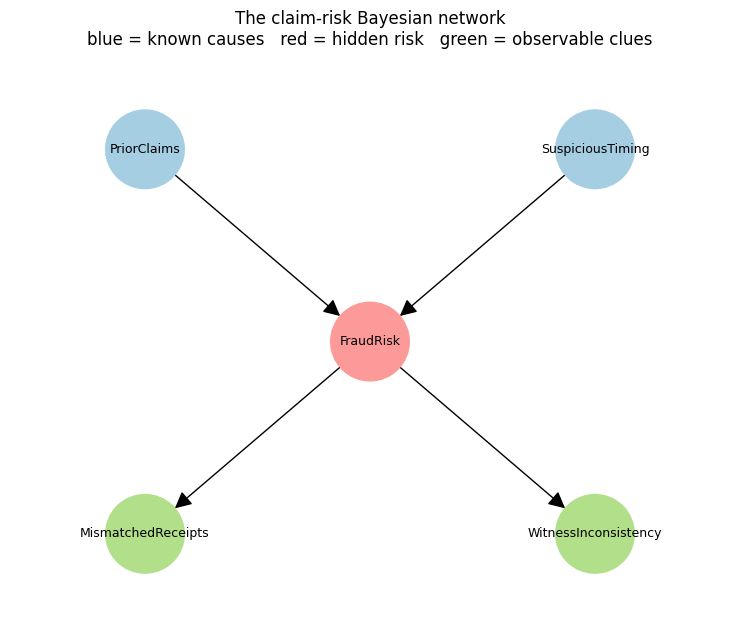

In [ ]:

# the DAG structure -- who influences whom (no probabilities yet, just edges)
edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

G = nx.DiGraph(edges)

pos = {
    "PriorClaims": (-1, 1),
    "SuspiciousTiming": (1, 1),
    "FraudRisk": (0, 0),
    "MismatchedReceipts": (-1, -1),
    "WitnessInconsistency": (1, -1),
}

color_by_node = {
    "PriorClaims": "#a6cee3",
    "SuspiciousTiming": "#a6cee3",
    "FraudRisk": "#fb9a99",
    "MismatchedReceipts": "#b2df8a",
    "WitnessInconsistency": "#b2df8a",
}
# build the color list in G's own node order -- NEVER assume it matches the
# order nodes were typed in a dict or list above; a DiGraph built from an
# edge list orders nodes by first appearance across edges, which is easy
# to get subtly wrong (we did, the first time we wrote this cell)
node_colors = [color_by_node[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color=node_colors, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, arrowsize=25, arrowstyle="-|>", node_size=3200,
                        connectionstyle="arc3,rad=0.0", ax=ax)
ax.set_title("The claim-risk Bayesian network\nblue = known causes   red = hidden risk   green = observable clues")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.5, 1.5)
ax.axis("off")
plt.tight_layout()
plt.show()


Recall our scenario from Module 9: five nodes, four arrows.

We touched on *why* the arrows point that way, but we never really
questioned whether we had the right arrows. They were simply given.
Module 10 then asked whether the network's **numbers** (the CPTs) could be
trusted -- using joint probability to catch anomalies and checking whether
the data's distribution had shifted over time. But even there, we still
trusted the **shape** (the arrows) without ever asking where that shape
came from.

This module asks exactly that question: if nobody hands you the arrows,
can you find them yourself, from nothing but a table of data? And just as
important -- when can you trust what you find, and when does the method
quietly lie to you?


## Part 0 — Recap: what we're building on

- **A DAG** (Directed Acyclic Graph) is a set of nodes connected by arrows,
  with no way to follow the arrows in a circle back to where you started.
  Our fraud network is a DAG: five nodes, four arrows, no cycles.
- **A CPT** (Conditional Probability Table) sits on each node and says how
  likely that node's own values are, given its parents' values. `FraudRisk`'s
  CPT says how likely High/Low risk is, given `PriorClaims` and
  `SuspiciousTiming`.
- **The factorization formula** lets you multiply a node's CPT value by its
  parents' CPT values (and so on up the chain) to get the probability of one
  entire, specific combination of every variable at once. This is what
  Module 10 reused as an anomaly score.
- **A fork**: one cause, two effects (`FraudRisk` causing both
  `MismatchedReceipts` and `WitnessInconsistency`). The two effects end up
  correlated with each other even though neither one causes the other --
  they're just both downstream of the same thing.
- **A collider**: two causes, one shared effect (`PriorClaims` and
  `SuspiciousTiming` both causing `FraudRisk`). The two causes start out
  *unrelated* to each other -- but the moment you condition on (learn the
  value of) the shared effect, they become related. This is "explaining
  away," and it's going to matter a lot in Part 3.

Everything new in this module is really just these same ideas, run in a
direction Module 9 never asked them to run in: instead of *using* a known
graph to reason about probabilities, we're going to *recover* the graph
itself from raw data.


In [ ]:
# Rebuilding the exact Module 9 network -- our ground truth for this module.
# Every discovery algorithm below will be judged against these same arrows.
edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

Where would a graph like this actually come from in a real business? Not
from nowhere. It would almost always come from historical practice -- years
of SIU (Special Investigations Unit) case reviews, actuaries and fraud
analysts noticing which patterns kept showing up in confirmed fraud cases,
maybe industry-wide fraud-indicator research layered on top. Someone with
real domain expertise looked at a pile of past claims and said "claims with
a prior history and odd timing keep turning out to be the risky ones, and
risky claims keep showing up with messy paperwork and shaky witnesses" --
and that expertise got written down.

That's worth saying plainly, because it changes how we move forward: it isn't an arbitrary guess, and it isn't nothing -- but it's still
**asserted, not verified**. "An expert noticed this pattern across years of
cases" is a genuinely strong starting point, and also exactly the kind of
belief that can quietly go stale, encode the expert's own blind spots, or
mistake a correlation they've only ever seen together for an actual cause.
Historical practice earns a graph worth taking seriously. It doesn't earn a
graph that's immune to being checked -- which is exactly what the rest of
this module puts to the test.

In [ ]:
def build_fraud_model(fraud_cpt_values):
    cpd_prior = TabularCPD("PriorClaims", 2, [[0.15], [0.85]],
                            state_names={"PriorClaims": ["Yes", "No"]})
    cpd_timing = TabularCPD("SuspiciousTiming", 2, [[0.10], [0.90]],
                             state_names={"SuspiciousTiming": ["Yes", "No"]})
    cpd_fraud = TabularCPD(
        "FraudRisk", 2, fraud_cpt_values,
        evidence=["PriorClaims", "SuspiciousTiming"], evidence_card=[2, 2],
        state_names={"FraudRisk": ["High", "Low"], "PriorClaims": ["Yes", "No"],
                     "SuspiciousTiming": ["Yes", "No"]},
    )
    cpd_receipts = TabularCPD(
        "MismatchedReceipts", 2, [[0.75, 0.05], [0.25, 0.95]],
        evidence=["FraudRisk"], evidence_card=[2],
        state_names={"MismatchedReceipts": ["Yes", "No"], "FraudRisk": ["High", "Low"]},
    )
    cpd_witness = TabularCPD(
        "WitnessInconsistency", 2, [[0.65, 0.04], [0.35, 0.96]],
        evidence=["FraudRisk"], evidence_card=[2],
        state_names={"WitnessInconsistency": ["Yes", "No"], "FraudRisk": ["High", "Low"]},
    )
    m = DiscreteBayesianNetwork(edges)
    m.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_receipts, cpd_witness)
    assert m.check_model(), "model failed validation"
    return m

FRAUD_CPT = [[0.90, 0.55, 0.50, 0.03],
             [0.10, 0.45, 0.50, 0.97]]

`FRAUD_CPT` isn't the only CPT in this network — every node has one. A CPT
can be as simple as the frequency-of-occurrence numbers we just discussed:
count how often something happened, and that count becomes the table.

One small terminology note before going further: you'll see `TabularCPD` in the code, not `TabularCPT`. **CPD** stands for
*Conditional Probability Distribution* — the general idea of "a probability
distribution for one variable, conditioned on its parents." A **CPT**
(Conditional Probability Table) is just what that distribution looks like
once you write it out as an actual table of numbers for discrete variables
like ours. Every CPT is a CPD; `TabularCPD` is pgmpy's name for the object
that holds one. We'll keep calling them CPTs, since that's the concrete
form every one of ours takes.

There are five CPTs total, one per node in the network, and they all get
built the same way:

```python
cpd_prior    = TabularCPD("PriorClaims", 2, [[0.15], [0.85]], ...)
cpd_timing   = TabularCPD("SuspiciousTiming", 2, [[0.10], [0.90]], ...)
cpd_fraud    = TabularCPD("FraudRisk", 2, fraud_cpt_values, evidence=["PriorClaims","SuspiciousTiming"], ...)
cpd_receipts = TabularCPD("MismatchedReceipts", 2, [[0.75,0.05],[0.25,0.95]], evidence=["FraudRisk"], ...)
cpd_witness  = TabularCPD("WitnessInconsistency", 2, [[0.65,0.04],[0.35,0.96]], evidence=["FraudRisk"], ...)
```

Every node gets exactly one CPT: `PriorClaims`'s own, `SuspiciousTiming`'s
own, `FraudRisk`'s (which is `FRAUD_CPT`), `MismatchedReceipts`'s, and
`WitnessInconsistency`'s. Two of them (`PriorClaims`, `SuspiciousTiming`)
have no evidence at all -- they're root nodes, so their CPT is just an
unconditional probability. The other three are conditioned on their
parent(s).

The CPTs are attached to the model, our `DiscreteBayesianNetwork` object with one line:
```python
m.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_receipts, cpd_witness)
```

From that point on, all five CPTs live *inside* the
`DiscreteBayesianNetwork` object itself (`model`, in the notebook) --
pgmpy keeps them internally and hands them back on request via
`model.get_cpds()`. You've also seen the notebook build a plain Python
dictionary right after that, for convenience:
```python
cpds = {c.variable: c for c in model.get_cpds()}
```
That `cpds` dict is nothing new -- it's just those same five CPT objects,
now reachable by name (`cpds["FraudRisk"]`) instead of having to search a
list. It's used constantly later (in `joint_prob_row`, in
`cpd_to_dataframe`) precisely so the code doesn't have to know ahead of
time which CPT it needs.

In [ ]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

FRAUD_CPT = [[0.90, 0.55, 0.50, 0.03],
             [0.10, 0.45, 0.50, 0.97]]

cpd_prior = TabularCPD("PriorClaims", 2, [[0.15], [0.85]],
                        state_names={"PriorClaims": ["Yes", "No"]})
cpd_timing = TabularCPD("SuspiciousTiming", 2, [[0.10], [0.90]],
                         state_names={"SuspiciousTiming": ["Yes", "No"]})
cpd_fraud = TabularCPD("FraudRisk", 2, FRAUD_CPT,
    evidence=["PriorClaims", "SuspiciousTiming"], evidence_card=[2, 2],
    state_names={"FraudRisk": ["High", "Low"], "PriorClaims": ["Yes", "No"],
                 "SuspiciousTiming": ["Yes", "No"]})
cpd_receipts = TabularCPD("MismatchedReceipts", 2, [[0.75, 0.05], [0.25, 0.95]],
    evidence=["FraudRisk"], evidence_card=[2],
    state_names={"MismatchedReceipts": ["Yes", "No"], "FraudRisk": ["High", "Low"]})
cpd_witness = TabularCPD("WitnessInconsistency", 2, [[0.65, 0.04], [0.35, 0.96]],
    evidence=["FraudRisk"], evidence_card=[2],
    state_names={"WitnessInconsistency": ["Yes", "No"], "FraudRisk": ["High", "Low"]})

true_model = DiscreteBayesianNetwork(edges)
true_model.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_receipts, cpd_witness)
assert true_model.check_model()
print("Model built. CPDs attached:", [c.variable for c in true_model.get_cpds()])

Model built. CPDs attached: ['PriorClaims', 'SuspiciousTiming', 'FraudRisk', 'MismatchedReceipts', 'WitnessInconsistency']


In [ ]:
import itertools
import pandas as pd

cpds = {c.variable: c for c in true_model.get_cpds()}

variables = ["PriorClaims", "SuspiciousTiming", "FraudRisk",
             "MismatchedReceipts", "WitnessInconsistency"]
state_options = {
    "PriorClaims": ["Yes","No"], "SuspiciousTiming": ["Yes","No"],
    "FraudRisk": ["High","Low"], "MismatchedReceipts": ["Yes","No"],
    "WitnessInconsistency": ["Yes","No"],
}

rows = []
for combo in itertools.product(*[state_options[v] for v in variables]):
    assignment = dict(zip(variables, combo))
    row = {}
    product = 1.0
    for node in variables:
        cpd = cpds[node]
        kwargs = {node: assignment[node]}
        for parent in cpd.variables[1:]:
            kwargs[parent] = assignment[parent]
        value = cpd.get_value(**kwargs)
        product *= value
        row[node] = f"{assignment[node]} ({value:.2f})"
    row["joint probability"] = round(product, 6)
    rows.append(row)

full_df = pd.DataFrame(rows).sort_values("joint probability", ascending=False).reset_index(drop=True)
full_df.head()

,PriorClaims,SuspiciousTiming,FraudRisk,MismatchedReceipts,WitnessInconsistency,joint probability
0,No (0.85),No (0.90),Low (0.97),No (0.95),No (0.96),0.676750
1,Yes (0.15),No (0.90),Low (0.45),No (0.95),No (0.96),0.055404
2,No (0.85),Yes (0.10),Low (0.50),No (0.95),No (0.96),0.038760
3,Yes (0.15),No (0.90),High (0.55),Yes (0.75),Yes (0.65),0.036197
4,No (0.85),No (0.90),Low (0.97),Yes (0.05),No (0.96),0.035618


In [ ]:
import itertools
import pandas as pd

def cpd_to_dataframe(cpd):
    var = cpd.variable
    var_states = cpd.state_names[var]
    evidence_vars = cpd.variables[1:]
    evidence_states = [cpd.state_names[e] for e in evidence_vars]
    rows = []
    for idx in itertools.product(*[range(len(s)) for s in evidence_states]):
        row = {ev: states[i] for ev, states, i in zip(evidence_vars, evidence_states, idx)}
        for vi, vs in enumerate(var_states):
            row[f"{var}={vs}"] = cpd.values[(vi,) + idx]
        rows.append(row)
    return pd.DataFrame(rows)

for node in ["PriorClaims", "SuspiciousTiming", "FraudRisk", "MismatchedReceipts", "WitnessInconsistency"]:
    cpd = true_model.get_cpds(node)
    print(f"--- {node} ---")
    display(cpd_to_dataframe(cpd))

--- PriorClaims ---


,PriorClaims=Yes,PriorClaims=No
0,0.15,0.85


--- SuspiciousTiming ---


,SuspiciousTiming=Yes,SuspiciousTiming=No
0,0.1,0.9


--- FraudRisk ---


,PriorClaims,SuspiciousTiming,FraudRisk=High,FraudRisk=Low
0,Yes,Yes,0.90,0.10
1,Yes,No,0.55,0.45
2,No,Yes,0.50,0.50
3,No,No,0.03,0.97


--- MismatchedReceipts ---


,FraudRisk,MismatchedReceipts=Yes,MismatchedReceipts=No
0,High,0.75,0.25
1,Low,0.05,0.95


--- WitnessInconsistency ---


,FraudRisk,WitnessInconsistency=Yes,WitnessInconsistency=No
0,High,0.65,0.35
1,Low,0.04,0.96


PRIORCLAIMS_CPT = [[0.15],
                    [0.85]]

SUSPICIOUSTIMING_CPT = [[0.10],
                         [0.90]]

FRAUD_CPT = [[0.90, 0.55, 0.50, 0.03],
             [0.10, 0.45, 0.50, 0.97]]

MISMATCHEDRECEIPTS_CPT = [[0.75, 0.05],
                           [0.25, 0.95]]

WITNESSINCONSISTENCY_CPT = [[0.65, 0.04],
                             [0.35, 0.96]]

That's the full picture of what `true_model` is actually built from -- five
CPTs, each one either asserted directly or traceable back to historical
practice, multiplying together into the joint probability of any single
claim. From here on, `true_model` stops being something we're inspecting
and becomes something we're testing: it's the **ground truth** the rest of
this module checks algorithms against. Every discovery algorithm below --
starting with `networkx`, then PC, then GES -- will be handed only sampled
*data* from this network, never `true_model` or its CPTs directly, and
judged on whether it can find its way back to the same five nodes and four
arrows we just built by hand.


## Part 1 — Correlation does not equal causation

Here's the claim this part has to make concrete, not just assert: two
variables can move together in your data with neither one causing the
other at all. Module 9 already contains the proof, if you look at the right
pair.

`MismatchedReceipts` and `WitnessInconsistency` never point at each other in
the true graph -- there's no arrow between them. Both of them are only
connected to `FraudRisk`. That's a **fork**: one shared cause, two effects.
If you only had a spreadsheet of claims and never saw the arrows, you'd
still notice these two columns tend to go up and down together. It would be
a mistake to conclude "mismatched receipts cause witnesses to be
inconsistent," or the reverse -- they're just both symptoms of the same
underlying thing.




In [ ]:

from pgmpy.sampling import BayesianModelSampling

sample = BayesianModelSampling(true_model).forward_sample(size=5000, seed=0, show_progress=False)

# turn Yes/No into 1/0 just to compute a correlation number
numeric = sample.replace({"Yes": 1, "No": 0, "High": 1, "Low": 0})

corr_receipts_witness = numeric["MismatchedReceipts"].corr(numeric["WitnessInconsistency"])
corr_priorclaims_timing = numeric["PriorClaims"].corr(numeric["SuspiciousTiming"])

print(f"Correlation(MismatchedReceipts, WitnessInconsistency) = {corr_receipts_witness:.3f}")
print("  -- correlated, but NO arrow between them. Both caused by FraudRisk (a fork).")
print()
print(f"Correlation(PriorClaims, SuspiciousTiming)            = {corr_priorclaims_timing:.3f}")
print("  -- essentially zero. These two are built to be independent causes of FraudRisk,")
print("     and with nothing else in the picture, that's exactly what the data shows.")


Correlation(MismatchedReceipts, WitnessInconsistency) = 0.436
  -- correlated, but NO arrow between them. Both caused by FraudRisk (a fork).

Correlation(PriorClaims, SuspiciousTiming)            = 0.003
  -- essentially zero. These two are built to be independent causes of FraudRisk,
     and with nothing else in the picture, that's exactly what the data shows.


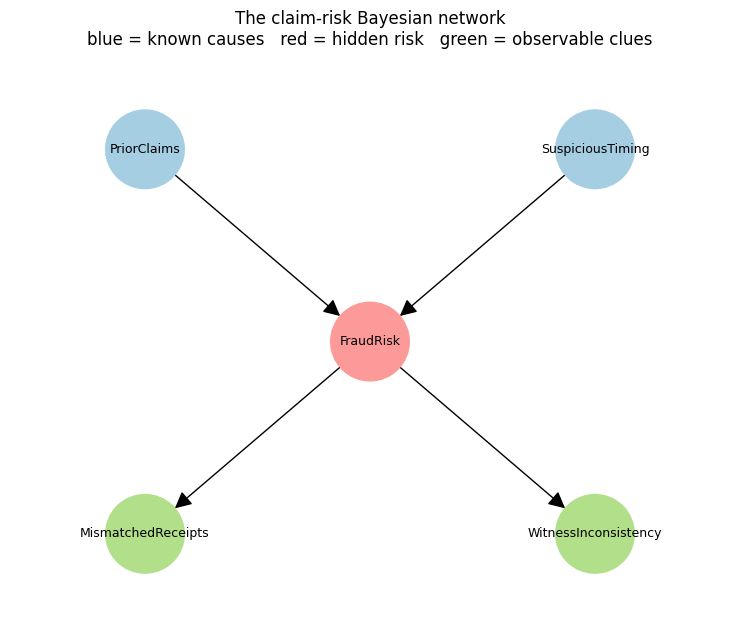

In [ ]:

# the DAG structure -- who influences whom (no probabilities yet, just edges)
edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

G = nx.DiGraph(edges)

pos = {
    "PriorClaims": (-1, 1),
    "SuspiciousTiming": (1, 1),
    "FraudRisk": (0, 0),
    "MismatchedReceipts": (-1, -1),
    "WitnessInconsistency": (1, -1),
}

color_by_node = {
    "PriorClaims": "#a6cee3",
    "SuspiciousTiming": "#a6cee3",
    "FraudRisk": "#fb9a99",
    "MismatchedReceipts": "#b2df8a",
    "WitnessInconsistency": "#b2df8a",
}
# build the color list in G's own node order -- NEVER assume it matches the
# order nodes were typed in a dict or list above; a DiGraph built from an
# edge list orders nodes by first appearance across edges, which is easy
# to get subtly wrong (we did, the first time we wrote this cell)
node_colors = [color_by_node[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color=node_colors, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, arrowsize=25, arrowstyle="-|>", node_size=3200,
                        connectionstyle="arc3,rad=0.0", ax=ax)
ax.set_title("The claim-risk Bayesian network\nblue = known causes   red = hidden risk   green = observable clues")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.5, 1.5)
ax.axis("off")
plt.tight_layout()
plt.show()



Hold on to that second number (`PriorClaims`/`SuspiciousTiming` correlation,
should print close to `0.00`) -- Part 3 is going to break it on purpose, and
you'll want a clean "before" number to compare against.

This is the whole motivation for the rest of the module: correlation is
cheap to compute and can be deeply misleading about *why* two things move
together. A causal arrow is a much stronger, much more useful claim -- and
the question is whether you can recover one from data alone.



## Part 2 — DAGs, meet NetworkX directly

Every network we've built this semester has been a `networkx`
graph -- `pgmpy`'s `DiscreteBayesianNetwork` is built directly on top of
`networkx.DiGraph`. The CPTs were always a separate layer sitting on top of
an ordinary graph structure underneath.

This matters because **most graph work outside this course has no CPTs at
all** -- just nodes and edges, used for a completely different kind of
question (who's connected to whom, how far apart are two nodes, is this
structure even acyclic). `networkx` is the plain, general-purpose tool for
that -- no probability, no causality, just graph shape. Let's use it
directly, with nothing probabilistic attached.


In [ ]:

# Build the SAME true graph, but as a plain networkx DiGraph -- no CPTs,
# no probabilities, just nodes and arrows.
G_true = nx.DiGraph()
G_true.add_edges_from(edges)

print("Nodes:", list(G_true.nodes()))
print("Edges:", list(G_true.edges()))
print()
print("Is this actually acyclic? ", nx.is_directed_acyclic_graph(G_true))
print("In-degree of FraudRisk (how many arrows point INTO it):",
      G_true.in_degree("FraudRisk"))
print("Out-degree of FraudRisk (how many arrows point OUT of it):",
      G_true.out_degree("FraudRisk"))


Nodes: ['PriorClaims', 'FraudRisk', 'SuspiciousTiming', 'MismatchedReceipts', 'WitnessInconsistency']
Edges: [('PriorClaims', 'FraudRisk'), ('FraudRisk', 'MismatchedReceipts'), ('FraudRisk', 'WitnessInconsistency'), ('SuspiciousTiming', 'FraudRisk')]

Is this actually acyclic?  True
In-degree of FraudRisk (how many arrows point INTO it): 2
Out-degree of FraudRisk (how many arrows point OUT of it): 2


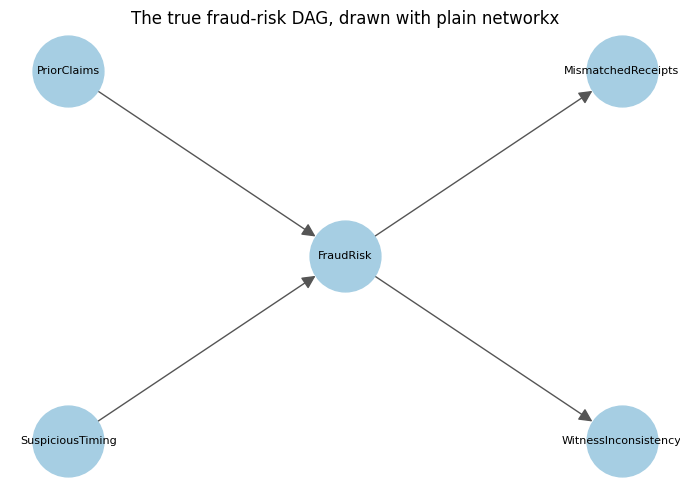

In [ ]:

fig, ax = plt.subplots(figsize=(7, 5))
pos = {
    "PriorClaims": (0, 1), "SuspiciousTiming": (0, -1),
    "FraudRisk": (1, 0),
    "MismatchedReceipts": (2, 1), "WitnessInconsistency": (2, -1),
}
nx.draw(G_true, pos, ax=ax, with_labels=True, node_color="#a6cee3",
        node_size=2600, font_size=8, arrowsize=20, edge_color="#555555")
ax.set_title("The true fraud-risk DAG, drawn with plain networkx")
plt.tight_layout()
plt.show()



Nothing above required a CPT or a probability -- `is_directed_acyclic_graph`,
in-degree, out-degree, the drawing itself, all of it is pure graph structure.
This is the layer every technique in this module (and, later, things like
knowledge graphs) actually sits on. Keep this picture in mind; the rest of
the module is about algorithms that try to *reconstruct* a drawing like this
one from nothing but the data it would produce.



## Part 3 — Constraint-based search: the PC algorithm

Here's the idea in one sentence: **the PC (Peter-Clark) algorithm runs d-separation backwards.** In Module 9, you were given the graph and used d-separation to predict which variables should be independent. The PC algorithm is handed only the *data*, tests every pair of variables for independence, and uses the pattern of "these two are independent, those two aren't" to work out
what the graph must have looked like.

d-separation is a purely graphical rule: by looking at the shape of a DAG
alone -- no probabilities needed -- you can predict which variables are
guaranteed to be independent, and which pairs become dependent only once
you condition on (learn the value of) some other variable. Two nodes are
**d-separated** if every path between them is "blocked"; if even one path
stays open, they're **d-connected**, and the Markov condition says
d-connected variables are (generically) dependent.

Paths get blocked differently depending on the shape they pass through:

- **Chains and forks** (`A -> C -> B` or `A <- C -> B`): open by default,
  blocked once you condition on the middle node `C`. This is
  `MismatchedReceipts` and `WitnessInconsistency` from Part 1 -- a fork
  through `FraudRisk`. Leave `FraudRisk` unconditioned and they're
  correlated; condition on it and that correlation disappears, because
  `FraudRisk` was the entire reason they moved together.
- **Colliders** (`A -> C <- B`): the opposite behavior -- *blocked* by
  default, and *opened* the moment you condition on `C` (or anything
  downstream of it). This is `PriorClaims` and `SuspiciousTiming` from
  Module 9 -- marginally independent, but dependent once `FraudRisk` is
  known, which is exactly "explaining away."

In Module 9, you were handed the graph and used this rule to *predict*
which variables should turn out independent. The PC algorithm runs that
same logic in reverse: it's handed only the data, runs independence tests
on every pair (and every pair conditioned on various other subsets), and
uses the resulting pattern -- "these two are independent, those two
aren't" -- to work backward to the one graph shape that would have produced
exactly that pattern of blocked and open paths.

Rough sketch of what it does:

1. Start with every variable connected to every other variable (a fully
   connected, undirected mess).
2. For every pair, test: are these two independent (or independent once you
   condition on some other variables)? If yes, **delete the edge between
   them** -- a real edge wouldn't let you "explain away" the connection like
   that.
3. Whatever edges survive, figure out their direction using the one piece of
   asymmetric evidence available: colliders. Remember from Module 9 --
   `PriorClaims` and `SuspiciousTiming` start out independent, but become
   dependent once you condition on `FraudRisk`. That specific signature
   (independent on their own, dependent once you condition on the node
   between them) is only possible if that middle node is a **collider** --
   both arrows point *into* it. Finding one collider like this lets you
   orient nearby edges too, by a simple rule: don't create a *new* collider
   that the data didn't support.

Let's hand the algorithm nothing but 5,000 sampled claims -- no edges, no
CPTs -- and see what it finds.


In [ ]:

from pgmpy.estimators import PC, GES

data_for_discovery = BayesianModelSampling(true_model).forward_sample(
    size=5000, seed=0, show_progress=False).astype(str)

pc_result = PC(data_for_discovery).estimate(
    variant="stable", ci_test="chi_square", significance_level=0.05, show_progress=False)

print("True edges:")
for e in edges:
    print(" ", e)
print()
print("PC-discovered directed edges:")
for e in pc_result.directed_edges:
    print(" ", e)
print("PC-discovered undirected edges (direction not determined):")
for e in pc_result.undirected_edges:
    print(" ", e)


True edges:
  ('PriorClaims', 'FraudRisk')
  ('SuspiciousTiming', 'FraudRisk')
  ('FraudRisk', 'MismatchedReceipts')
  ('FraudRisk', 'WitnessInconsistency')

PC-discovered directed edges:
  ('PriorClaims', 'FraudRisk')
  ('SuspiciousTiming', 'FraudRisk')
  ('FraudRisk', 'MismatchedReceipts')
  ('FraudRisk', 'WitnessInconsistency')
PC-discovered undirected edges (direction not determined):



The PC algorithm recovered **all four edges, fully directed, with every
arrow pointing the right way** -- from nothing but a table of Yes/No/High/Low
values. No one told it `FraudRisk` was in the middle.

Worth understanding *why* it managed to orient every single edge, not just
find the right ones. There's exactly one collider in this graph --
`PriorClaims -> FraudRisk <- SuspiciousTiming` -- and the independence test
pattern described above flags it. Once that one collider is pinned down,
a propagation rule kicks in for the rest: `FraudRisk` is now known to have
an arrow pointing *into* it from `PriorClaims`. If the edge to
`MismatchedReceipts` stayed undirected, pointing it *into* `FraudRisk` would
create a second collider the data never supported -- so it gets forced to
point *out*, `FraudRisk -> MismatchedReceipts`. One correctly-found collider
cascades into the whole graph's direction. Take that collider away (Part 5
does exactly this), and watch how much breaks.



## Part 4 — Score-based search: GES

PC asks, pair by pair, "are you two independent?" **GES (Greedy Equivalence
Search)** asks a completely different kind of question: "if I had to score
*entire candidate graphs* by how well they explain this data, which one
wins?" It starts with no edges at all, greedily adds the single edge that
improves the score the most, keeps going until adding edges stops helping,
then greedily removes edges the same way. The score itself (commonly BIC --
Bayesian Information Criterion, the same kind of score mentioned back in
Module 9's structure-learning discussion) rewards fitting the data well but
penalizes extra edges, so it doesn't just connect everything to everything.

Different mechanism, same question. Let's see if it lands in the same
place.


In [ ]:

ges_result = GES(data_for_discovery).estimate()

print("GES-discovered directed edges:")
for e in ges_result.directed_edges:
    print(" ", e)
print("GES-discovered undirected edges:")
for e in ges_result.undirected_edges:
    print(" ", e)
print()
print("Same result as PC?",
      ges_result.directed_edges == pc_result.directed_edges
      and ges_result.undirected_edges == pc_result.undirected_edges)


GES-discovered directed edges:
  ('PriorClaims', 'FraudRisk')
  ('SuspiciousTiming', 'FraudRisk')
  ('FraudRisk', 'MismatchedReceipts')
  ('FraudRisk', 'WitnessInconsistency')
GES-discovered undirected edges:

Same result as PC? True



Same answer, from a completely different algorithmic strategy -- one testing
independence pair by pair, the other scoring whole candidate graphs. That
agreement is reassuring, not guaranteed: PC and GES don't always agree on
messier, real-world data. When they do agree, it's a genuinely useful
sanity check that the structure you're seeing isn't just an artifact of one
particular method's assumptions.



## Part 5 — When discovery breaks: latent confounding

Both algorithms above quietly assumed something big: **every common cause of
two variables is itself measured and sitting in the dataset.** This
assumption has a name -- *causal sufficiency* -- and the moment it's false,
both algorithms don't just get a little fuzzy. They can fail in a specific,
predictable way.

Here's the setup: suppose there's a real-world factor -- say, regional
economic stress -- that pushes up *both* `PriorClaims` (more people filing
claims who've filed before) and `SuspiciousTiming` (more people filing
right before a policy lapses) across an entire region, independently of
whether any individual claim is actually fraudulent. Nobody records
"regional economic stress" as a column. It's a **latent (unmeasured)
confounder** -- a hidden common cause sitting above two variables that, in
the true graph, aren't supposed to be connected to each other at all.

Recall from Part 1: with no confounding, `Correlation(PriorClaims,
SuspiciousTiming)` came out essentially `0.00`. Let's add the hidden factor
back in, generate data the same way a real dataset would come to you (the
hidden factor doing its work in the background, never appearing as a
column), and see what the algorithms do with it.


The classic statistical lesson of shark bites and ice cream sales
illustrates exactly this trap. During the summer, ice cream sales and shark
attacks spike together along the same beach -- and it would be easy to
assume one somehow drives the other. Neither does. Both are driven entirely
by a hidden factor that neither column records: warm weather. The heat
independently pushes more people to buy ice cream to cool off, and pushes
larger crowds into the ocean to swim, which naturally raises the odds of a
shark encounter. Nothing in an ice-cream-sales-and-shark-attacks
spreadsheet would ever reveal that on its own -- you'd need to already
suspect temperature was out there and go measure it.

Our own network has exactly the same trap built in, just with claims
instead of beaches. The hidden variable below is called `H`, meant to
represent something like regional economic stress, and it plays the same
role "warm weather" played above: it pushes both `PriorClaims` and
`SuspiciousTiming` up together, without either one causing the other, and
without `H` ever showing up as a column in the data PC or GES are handed.

One more thing worth flagging before moving on: latent confounding is about
a cause you can't see, acting on data you already have. A later module
picks up a related but sharper question -- Judea Pearl's third rung of
causal reasoning, **counterfactuals**: not "what's hidden in the data I
have," but "what *would have happened* to this one specific claim if one
thing about it had been different, with everything else held fixed." Keep
that question in the back of your mind -- it's coming back.

In [ ]:

rng = np.random.default_rng(3)
n = 6000

# H = the hidden regional-stress factor. It is NEVER given to PC or GES below --
# only PriorClaims, SuspiciousTiming, FraudRisk, MismatchedReceipts, and
# WitnessInconsistency are. This mirrors a real dataset: whatever H represents
# was simply never recorded.
H = rng.binomial(1, 0.5, n)
PriorClaims = rng.binomial(1, np.where(H == 1, 0.55, 0.05))
SuspiciousTiming = rng.binomial(1, np.where(H == 1, 0.45, 0.03))

def fraud_p(pc, st):
    table = {(1, 1): 0.90, (1, 0): 0.55, (0, 1): 0.50, (0, 0): 0.03}
    return table[(pc, st)]

FraudRisk = np.array([rng.binomial(1, fraud_p(pc, st))
                       for pc, st in zip(PriorClaims, SuspiciousTiming)])
MismatchedReceipts = rng.binomial(1, np.where(FraudRisk == 1, 0.75, 0.05))
WitnessInconsistency = rng.binomial(1, np.where(FraudRisk == 1, 0.65, 0.04))

confounded = pd.DataFrame({
    "PriorClaims": PriorClaims, "SuspiciousTiming": SuspiciousTiming,
    "FraudRisk": FraudRisk, "MismatchedReceipts": MismatchedReceipts,
    "WitnessInconsistency": WitnessInconsistency,
})

corr_with_confounding = np.corrcoef(PriorClaims, SuspiciousTiming)[0, 1]
print(f"Correlation(PriorClaims, SuspiciousTiming) WITH hidden H driving both: "
      f"{corr_with_confounding:.3f}")
print(f"  (compare to ~0.00 in Part 1, with no hidden confounder)")


Correlation(PriorClaims, SuspiciousTiming) WITH hidden H driving both: 0.276
  (compare to ~0.00 in Part 1, with no hidden confounder)


In [ ]:

confounded_str = confounded.astype(str)

pc_confounded = PC(confounded_str).estimate(
    variant="stable", ci_test="chi_square", significance_level=0.05, show_progress=False)
ges_confounded = GES(confounded_str).estimate()

print("PC directed edges (H withheld):  ", pc_confounded.directed_edges)
print("PC undirected edges (H withheld):", pc_confounded.undirected_edges)
print()
print("GES directed edges (H withheld):  ", ges_confounded.directed_edges)
print("GES undirected edges (H withheld):", ges_confounded.undirected_edges)


PC directed edges (H withheld):   set()
PC undirected edges (H withheld): {('FraudRisk', 'PriorClaims'), ('PriorClaims', 'SuspiciousTiming'), ('FraudRisk', 'MismatchedReceipts'), ('FraudRisk', 'SuspiciousTiming'), ('FraudRisk', 'WitnessInconsistency')}

GES directed edges (H withheld):   set()
GES undirected edges (H withheld): {('WitnessInconsistency', 'FraudRisk'), ('FraudRisk', 'PriorClaims'), ('FraudRisk', 'MismatchedReceipts'), ('SuspiciousTiming', 'PriorClaims'), ('FraudRisk', 'SuspiciousTiming')}



Two things went wrong at once, and both are worth naming precisely:

1. **A spurious edge appeared.** `PriorClaims` and `SuspiciousTiming` now
   show up connected -- an edge that doesn't correspond to either one
   causing the other. It exists only because something neither algorithm
   can see (`H`) is pulling on both of them at once.
2. **Every single edge lost its direction.** Compare this to Part 3: there,
   one correctly-detected collider at `FraudRisk` let the direction cascade
   through the whole graph. Here, `PriorClaims` and `SuspiciousTiming` are
   no longer independent on their own (because `H` makes them dependent
   before you even get to `FraudRisk`), so the collider signature the whole
   cascade depended on never shows up. One hidden variable didn't just add
   one wrong edge -- it silently disabled the mechanism both algorithms use
   to figure out direction *anywhere* in the graph.

This is the sharpest, most humbling lesson in causal discovery: **the
algorithm isn't being sloppy -- it's blind to anything it was never shown.**
A PC or GES result that looks confident and fully directed is not proof that
no hidden confounder exists; it only means none of your *measured* variables
exposed one. In practice, researchers reach for an algorithm built
specifically around this problem -- **FCI (Fast Causal Inference)** -- which,
instead of guessing a direction it isn't sure of, is designed to explicitly
flag "there may be a hidden common cause here" rather than silently drawing
an edge as if there weren't one. We won't run FCI here, but knowing it
exists -- and *why* it exists -- is the actual takeaway: any causal
discovery result is only as trustworthy as the assumption that you measured
everything that matters.



## Part 6 — Same graph-shaped thinking, a bigger world

Everything above used `networkx` for a narrow, specific job: discovering and
drawing a *causal* graph with five nodes. Graphs show up constantly outside
that narrow job too, and it's worth a quick, grounded tour of where -- using
the same small cast of claims, adjusters, and witnesses, so nothing new has
to be invented to follow along.

Two adjusters, four claims, one witness who happens to show up twice:


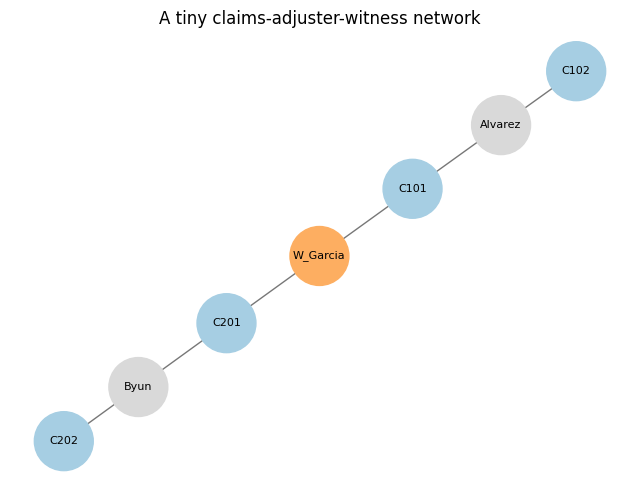

In [ ]:

claims_graph = nx.Graph()
claims_graph.add_edges_from([
    ("C101", "Alvarez"), ("C102", "Alvarez"),   # Alvarez handled C101, C102
    ("C201", "Byun"), ("C202", "Byun"),          # Byun handled C201, C202
    ("C101", "W_Garcia"), ("C201", "W_Garcia"),  # W_Garcia testified in BOTH
])

fig, ax = plt.subplots(figsize=(6.5, 5))
colors = ["#fdae61" if n.startswith("W_") else
          "#a6cee3" if n.startswith("C") else "#d9d9d9"
          for n in claims_graph.nodes()]
nx.draw(claims_graph, ax=ax, with_labels=True, node_color=colors,
        node_size=1800, font_size=8, edge_color="#777777")
ax.set_title("A tiny claims-adjuster-witness network")
plt.tight_layout()
plt.show()


Graphs show up constantly outside that narrow job too, with no causality or probability involved at all -- just "who's connected to whom." Worth a quick, grounded tour of where, using a new small scenario built on the same cast of characters this module has been using all along: claims, adjusters, and the people who testify on them.

Here we have **two claims adjusters, four claims, and one witness who
happens to be a witness twice.** `Alvarez` handled `C101` and `C102`. `Byun`
handled `C201` and `C202`. Nothing links Alvarez and Byun's claims to each
other -- except that the same witness, `W_Garcia`, testified on both `C101`
(Alvarez's claim) and `C201` (Byun's claim). Two edges mean two different
things here: a claim connects to the adjuster who *handled* it, and a claim
connects to the witness who *testified on* it.

This little graph has no causes, no CPTs, no probabilities, and hence no
arrows -- it's pure structure. The fraud network earlier needed arrows
because direction *meant* something (`FraudRisk` causes `MismatchedReceipts`,
not the other way around). Here, "Alvarez handled C101" and "C101 was
witnessed by W_Garcia" aren't causal claims pointing one way -- they're just
connections, so this graph is undirected. That's exactly the kind of data
the rest of this section runs on: first just drawn and inspected with plain
`networkx`, then used to show what a production-scale graph database like
Neo4j would do with the same idea at millions of nodes instead of seven,
then traversed to answer a question text search alone couldn't ("does Byun
share a witness with Alvarez?"), and finally used to show how a trained
model could learn a prediction from the graph's shape alone.


**NetworkX** is what's drawing the picture above, right now, in memory, in
this notebook. It's the right tool exactly as long as the graph fits
comfortably in memory and one person (you) is querying it in a script.

**Neo4j** solves a different problem: the same kind of graph, but with
millions of nodes, persisted in a real database, queried by many people at
once, continuously updated. The question "who shares a witness with
Alvarez's claims?" would be asked in a query language called Cypher instead
of Python -- something like:

```
MATCH (a:Adjuster {name:"Alvarez"})-[:HANDLED]->(c1:Claim)
      -[:WITNESSED_BY]->(w:Witness)<-[:WITNESSED_BY]-(c2:Claim)
      <-[:HANDLED]-(other:Adjuster)
RETURN other
```

(shown here for comparison only -- this needs a running Neo4j database, not
something this notebook sets up).

A **knowledge graph** isn't a tool at all -- it's the *data itself*: entities
(claims, adjusters, witnesses) and labeled relationships between them
(`HANDLED`, `WITNESSED_BY`). It's what both NetworkX and Neo4j actually
store; the only difference is where.


In [ ]:

# A GraphRAG-style question: plain text search would need the word "Byun" to
# appear near "Alvarez" in some document to connect them. Nothing here does.
# A graph traversal finds the connection anyway, by following relationships.

alvarez_claims = list(claims_graph.neighbors("Alvarez"))
witnesses_of_those_claims = set()
for c in alvarez_claims:
    witnesses_of_those_claims |= {n for n in claims_graph.neighbors(c) if n.startswith("W_")}

other_claims_via_shared_witness = set()
for w in witnesses_of_those_claims:
    other_claims_via_shared_witness |= set(claims_graph.neighbors(w))
other_claims_via_shared_witness -= set(alvarez_claims)

print("Alvarez's claims:", alvarez_claims)
print("Witnesses connected to those claims:", witnesses_of_those_claims)
print("Other claims reachable through a shared witness:", other_claims_via_shared_witness)

for c in other_claims_via_shared_witness:
    other_adjuster = [n for n in claims_graph.neighbors(c) if not n.startswith(("C", "W_"))]
    print(f"  {c} is handled by {other_adjuster} -- connected to Alvarez via a shared witness")


Alvarez's claims: ['C101', 'C102']
Witnesses connected to those claims: {'W_Garcia'}
Other claims reachable through a shared witness: {'C201'}
  C201 is handled by ['Byun'] -- connected to Alvarez via a shared witness



That's **GraphRAG** in miniature: instead of searching for text that sounds
similar to a question, you extract entities and relationships into a graph
first, then *traverse* it to answer multi-hop questions ("who's connected to
Alvarez's claims, two hops away?") that a similarity search over plain text
would have no mechanism for answering at all. Plain RAG is still the right
tool when the question really is "find me a passage that talks about X" --
GraphRAG earns its keep specifically when the question requires following a
chain of relationships like this one.

Last stop: what if, instead of *asking* the graph a question, you want a
model to *learn* a prediction from the graph's shape itself? That's what a
**Graph Neural Network (GNN)** does. No training here -- just the one
underlying idea, by hand, one hop at a time: each node updates its own
"risk score" by averaging it together with its neighbors' scores.


The idea is called **message passing**: every node updates its own score by
averaging itself together with its immediate neighbors' scores. Do that
once, and a node picks up a trace of whatever its direct neighbors were
holding. Do it again, and it picks up a trace of what *their* neighbors
were holding too -- so stacking more "hops" (layers, in a real GNN) lets
information travel further across the graph, the same way a rumor spreads
one person at a time.

Here's the scenario: `C201` is a confirmed fraud case, and nothing else in
the graph knows it yet -- every other node starts at a plain `0`. The
question is whether that signal can reach `C101`, a claim handled by a
different adjuster (`Alvarez` instead of `Byun`), connected to `C201` only
indirectly, through the witness they happen to share (`W_Garcia`). Watch
what `C101`'s score does after one hop of averaging, and then after two.

In [ ]:

fraud_score = {
    "C101": 0, "C102": 0, "C201": 1, "C202": 0,  # C201 is a confirmed fraud case
    "Alvarez": 0, "Byun": 0, "W_Garcia": 0,
}

def one_hop_update(scores, graph):
    updated = {}
    for node in graph.nodes():
        neighborhood_scores = [scores[node]] + [scores[nbr] for nbr in graph.neighbors(node)]
        updated[node] = float(np.mean(neighborhood_scores))
    return updated

after_1_hop = one_hop_update(fraud_score, claims_graph)
after_2_hops = one_hop_update(after_1_hop, claims_graph)

print("Known fraud signal starts only at C201.")
print()
print("C101's risk score:")
print(f"  before any hops:  {fraud_score['C101']:.3f}")
print(f"  after 1 hop:       {after_1_hop['C101']:.3f}  (C201 is 2 hops away -- too far to feel yet)")
print(f"  after 2 hops:      {after_2_hops['C101']:.3f}  (now it picks up a trace of C201's signal)")
print()
print(f"Shortest path, C101 to C201: {nx.shortest_path_length(claims_graph, 'C101', 'C201')} hops")


Known fraud signal starts only at C201.

C101's risk score:
  before any hops:  0.000
  after 1 hop:       0.000  (C201 is 2 hops away -- too far to feel yet)
  after 2 hops:      0.111  (now it picks up a trace of C201's signal)

Shortest path, C101 to C201: 2 hops



`C101` never changed anything about itself -- its own data is identical the
whole time. What changed is that the fraud signal from `C201` took exactly
two hops (through the shared witness, `W_Garcia`) to reach it. A real GNN
does this same neighbor-averaging idea with trained weights instead of a
plain average, stacks several of these "hop" layers, and learns to predict
something (is this claim part of a fraud ring?) from the *shape* of the
graph around each node -- not from that node's own features alone. You'd
reach for a GNN specifically when the connections between data points carry
real signal, and you have enough data to actually train on it; for a
network this small, hand-computing it, like above, tells you everything a
trained model would.

One last distinction worth being precise about, since all five of these
terms get used loosely: a **knowledge graph** is data (entities and
relationships). **NetworkX** and **Neo4j** are two different places to store
and query that data -- one in memory for notebook-scale work, one as a
persistent database for production scale. **GraphRAG** is one thing you can
*do* with that data -- answer multi-hop questions by traversal. A **GNN** is
a different thing you can do with it -- learn predictions from its shape.
Plain **RAG** is the sibling approach that skips the graph step entirely and
works on raw text similarity, which is the right call whenever the
relationships between things don't actually matter to the question being
asked.



## Wrap-up

What this module adds to Module 9 and Module 10, in one sentence: Module 9
trusted the arrows; Module 10 checked whether the numbers on those arrows
were still trustworthy; Module 11 asks where the arrows themselves are
allowed to come from, and how much to trust an answer to that question.

Quick recap:

1. **Correlation vs. causation** -- two variables can move together with
   neither causing the other, demonstrated directly on `MismatchedReceipts`
   and `WitnessInconsistency`, a textbook fork from Module 9.
2. **DAGs via plain NetworkX** -- the same graph structure that's been
   quietly underneath every Bayesian network all semester, used directly,
   with no CPTs attached.
3. **The PC algorithm (constraint-based)** -- runs d-separation in reverse,
   testing independence pair by pair, and recovered the entire true graph,
   fully directed, from raw sampled data.
4. **GES (score-based)** -- a completely different strategy (score whole
   candidate graphs instead of testing pairs) that landed on the exact same
   answer, a useful cross-check when two unrelated methods agree.
5. **Latent confounding** -- a single unmeasured variable created a spurious
   edge *and* destroyed every edge's direction at once, by quietly removing
   the one collider both algorithms depended on. The honest takeaway: a
   confident, fully-directed result is not proof that nothing was missed.
6. **The wider graph landscape** -- NetworkX and Neo4j as two places to put
   the same kind of data (notebook-scale vs. production-scale), a knowledge
   graph as the data itself, GraphRAG as multi-hop retrieval over it, and a
   GNN as a learned prediction from its shape -- all demonstrated on the
   same small claims-and-witness graph, no new scenario required.

**Where this goes next:** every technique in this module still needed
*labeled* variables to work with -- `PriorClaims`, `FraudRisk`, and so on,
already named and measured. The next natural question is what to do when
you don't even have that: raw, unlabeled data, and the task of finding
*any* meaningful structure in it at all. That's unsupervised learning and
clustering.


## Assignment

Please start a new text cell and write a reflection, about 100-150 words,
on the following: this module's sharpest lesson was that a causal discovery
algorithm isn't being sloppy when it gets fooled by a hidden confounder --
it's blind to anything it was never shown. Pick one moment from this module
-- the PC algorithm fully recovering the true DAG, the latent confounder
destroying every edge's direction at once, or the small claims-graph tour
in Part 6 -- and explain, in your own words, what that moment taught you
about the difference between "the algorithm found no evidence of X" and
"X isn't there."